In [1]:
from matplotlib import pyplot as plt
import pandas as pd
import numpy as np
import seaborn as sns


from el_hd_plasticity.rna_seq.helpers import *

plt.rcParams['pdf.fonttype']=42

%load_ext autoreload
%autoreload 2 

%matplotlib inline


# Load gene info

In [2]:
glia = pd.read_csv('./geneIDs/glia.csv')

transmitters = pd.read_csv('./geneIDs/transmitters.csv')
receptors = pd.read_csv('./geneIDs/receptors.csv')

VgatedChannels = pd.read_csv('./geneIDs/VgatedChannels.csv')

neuropeptides = pd.read_csv('./geneIDs/neuropeptides.csv')

# Load the data

In [4]:
dat_wb = pd.read_csv("./data/lowCellSeq.csv")
celltyp_wb = [c.split("_")[0] for c in dat_wb.columns]
dat_wb = dat_wb.iloc[:,[i for i,t in enumerate(celltyp_wb) if ((t == "wholebrain") | (t == "gene"))]]

dat_ExR2 = pd.read_csv("./data/ExR2/merged_counts.txt",delimiter = '\t')
dat_EL1 = pd.read_csv("./data/EL/SS00027/merged_counts.txt",delimiter = '\t')
dat_EL2 = pd.read_csv("./data/EL/SS50573/merged_counts.txt",delimiter = '\t')
dat = dat_EL1
dat = dat.merge(dat_EL2, how = 'left', on = "gene_id")
dat = dat.merge(dat_ExR2, how = 'left', on = "gene_id")
dat = dat.merge(dat_wb, how = 'left', on = "gene_id")

dat = dat.set_index("gene_id", inplace = False)
dat = dat.iloc[:,1:]


# Remove bad samples
dat = dat.drop(['Q5_F01_Sample_MB233B', 'Q5_F02_Sample_MB136B', 
                'Q5_A03_Sample_MB233B', 'Q5_B03_Sample_MB233B',
                'Q5_H02_Sample_MB136B', 'Q5_C03_Sample_MB136B', 'Q5_D03_Sample_MB136B'], axis = 1)

dat = dat.drop(['gene_name_y'], axis = 1)
dat = dat.drop(['gene_name'], axis = 1)

In [5]:
MB136BMeanVals_lc = dat[[nm for nm in dat.columns if 'MB136B' in nm]].mean(axis=1)
MB233BMeanVals_lc = dat[[nm for nm in dat.columns if 'MB233B' in nm]].mean(axis=1)
SS00027MeanVals_lc = dat[[nm for nm in dat.columns if 'SS00027' in nm]].mean(axis=1)
SS50573MeanVals_lc = dat[[nm for nm in dat.columns if 'SS50573' in nm]].mean(axis=1)
WBMeanVals_lc = dat[[nm for nm in dat.columns if 'wholebrain' in nm]].mean(axis=1)
ctDiffsLowCell = pd.DataFrame({'MB136BDiff':(MB136BMeanVals_lc-WBMeanVals_lc),
                               'MB233BDiff':(MB233BMeanVals_lc-WBMeanVals_lc),
                               'SS00027Diff':(SS00027MeanVals_lc-WBMeanVals_lc),
                               'SS50573Diff':(SS50573MeanVals_lc-WBMeanVals_lc)
                              })
ctDiffsLowCell[ctDiffsLowCell >= 0] = 0
ctDiffsLowCell[ctDiffsLowCell < 0] = 1
ctDiffsLowCell[ctDiffsLowCell == 0] = -1

In [6]:
# Create a lookup table between line names and cell types
lines_to_celltypes = pd.DataFrame({'Line':['SS00027','SS50573',
                                           'MB233B','MB136B',
                                           'wholebrain'],'Cell Type':['EL(line 1)','EL(line 2)',
                                                                      'ExR2 (line 1)','ExR2 (line 2)',
                                                                      'wholebrain']})

dat.columns = [lines_to_celltypes.iloc[i]['Cell Type'] for c in dat.columns for i,l in enumerate(lines_to_celltypes['Line'].values) if l in c]

# Plot the raw data

### check for glial contamination

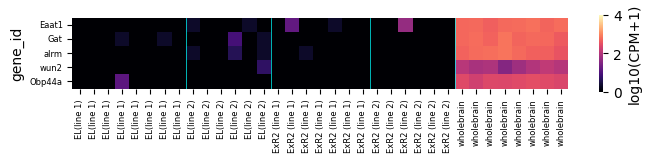

In [7]:
genes2plt = glia



# ax = fig.add_subplot()
fig, ax = plt_ht_map(genes2plt,dat,'CPM',4, figsize=[8,2], cmap='magma')
ax.axvline(x=8, color = 'cyan',linewidth=0.5)
ax.axvline(x=14, color = 'cyan',linewidth=0.5)
ax.axvline(x=21, color = 'cyan',linewidth=0.5)
ax.axvline(x=27, color = 'cyan',linewidth=0.5)
ax.set_aspect('equal')
ax.tick_params(axis='y') 



### neurotransmitter enzymes

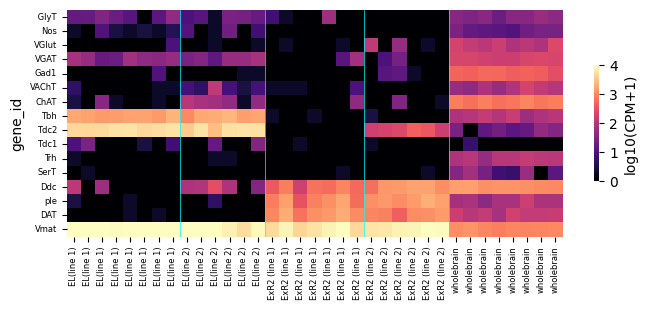

In [8]:
genes2plt = transmitters.iloc[16::-1,]

fig,ax = plt_ht_map(genes2plt,dat,'CPM',4, figsize=[8,3], cmap='magma')
ax.axvline(x=8, color = 'cyan',linewidth=0.5)
ax.axvline(x=14, color = 'cyan',linewidth=0.5)
ax.axvline(x=21, color = 'cyan',linewidth=0.5)
ax.axvline(x=27, color = 'cyan',linewidth=0.5)
ax.set_aspect('equal')
ax.tick_params(axis='y') 



### Take means across replicates and replot for main figure

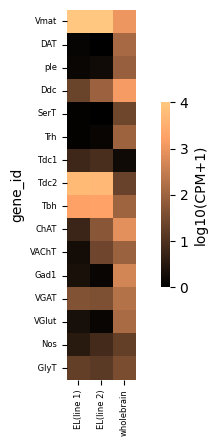

In [9]:
mask = []
for c in dat.columns:
    if 'EL' in c or 'wholebrain' in c:
        mask.append(True)
    else:
        mask.append(False)
el_dat = dat.loc[:,mask]


line1_mask = el_dat.columns.str.contains('line 1')
line2_mask = el_dat.columns.str.contains('line 2')
wholebrain_mask = el_dat.columns.str.contains('wholebrain')
el_dat_mu = pd.DataFrame({
                          'EL(line 1)':el_dat.loc[:,line1_mask].mean(axis=1),
                          'EL(line 2)':el_dat.loc[:,line2_mask].mean(axis=1),
                          'wholebrain':el_dat.loc[:,wholebrain_mask].mean(axis=1)})


genes2plt = transmitters

fig,ax = plt_ht_map(genes2plt,el_dat_mu,'CPM',4, cmap='copper')

ax.set_aspect('equal')
ax.tick_params(axis='y') 


### neurotransmitter and neuromodulator receptors

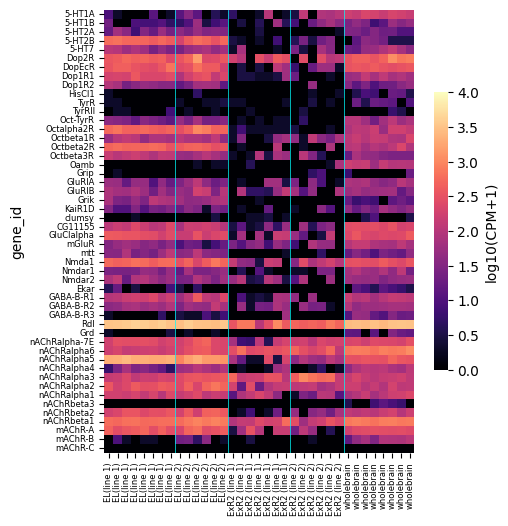

In [10]:
genes2plt = receptors

fig, ax = plt_ht_map(genes2plt,dat,'CPM',4, figsize=[5,12], cmap='magma', cbar_shrink=0.3)
ax.axvline(x=8, color = 'cyan',linewidth=0.5)
ax.axvline(x=14, color = 'cyan',linewidth=0.5)
ax.axvline(x=21, color = 'cyan',linewidth=0.5)
ax.axvline(x=27, color = 'cyan',linewidth=0.5)
ax.set_aspect('equal')
ax.tick_params(axis='y') 

plt.show()
    


### neuropeptides

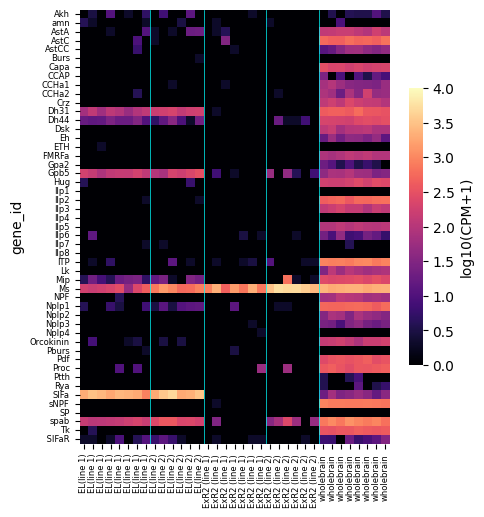

In [11]:
genes2plt = neuropeptides

fig, ax = plt_ht_map(genes2plt,dat,'CPM',4, figsize=[5,12], cmap='magma', cbar_shrink=0.3)
ax.axvline(x=8, color = 'cyan',linewidth=0.5)
ax.axvline(x=14, color = 'cyan',linewidth=0.5)
ax.axvline(x=21, color = 'cyan',linewidth=0.5)
ax.axvline(x=27, color = 'cyan',linewidth=0.5)
ax.set_aspect('equal')
ax.tick_params(axis='y') 

plt.show()
    


### voltage gated channels

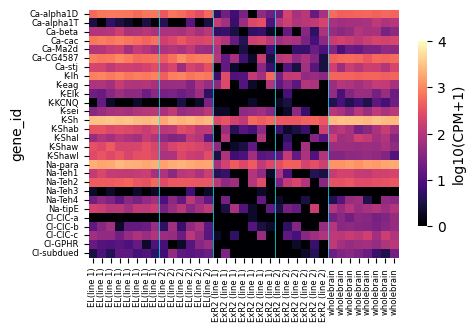

In [12]:
genes2plt = VgatedChannels


fig, ax = plt_ht_map(genes2plt,dat,'CPM',4, figsize=[5,12], cmap='magma', cbar_shrink=0.2)
ax.axvline(x=8, color = 'cyan',linewidth=0.5)
ax.axvline(x=14, color = 'cyan',linewidth=0.5)
ax.axvline(x=21, color = 'cyan',linewidth=0.5)
ax.axvline(x=27, color = 'cyan',linewidth=0.5)
ax.set_aspect('equal')
ax.tick_params(axis='y') 

plt.show()
    
